In [20]:
from langgraph.graph import START, END, StateGraph, MessagesState
from IPython.display import display, Image
import pandas
from langchain_core.documents import Document
from langchain_community.document_loaders import TextLoader
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from dotenv import load_dotenv
from langchain.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition

class MessagesState(MessagesState):
    documents: list[Document]

def indexing_data(state: MessagesState) -> MessagesState:
    # text = TextLoader(file_path="rules.txt", encoding="utf-8")
    # docs = text.load()

    with open("rules.txt", "r", encoding="utf-8") as file:
        text = file.read()

    chunks = text.split("\n\n\n")
    docs = []
    for i in chunks:
        docs.append(Document(i, metadata={"source": "rules.txt"}))

    # print(len(docs))
    return {'documents': docs}

def putting_data_to_the_vectorstore(state: MessagesState) -> MessagesState:
    some_document = state.get('documents')
    store.store.clear()
    store.add_documents(documents=some_document)
    return state;

def llm_node(state: MessagesState) -> MessagesState:
    return {"messages": [llm_with_tools.invoke(state.get("messages"))]}

@tool
def retrieve_context(query: str) -> list[Document]:
    """Retrieve information to help answer a query and return list of documents."""
    retrived_documents = store.similarity_search(query=query, k=2)
    contexts = "\n\n".join(f"{doc.page_content}" for doc in retrived_documents)
    print(f"Retrieved documents: {retrived_documents}\n\n\nContext documents: {contexts}")
    return retrived_documents


load_dotenv()


data_frame = pandas.read_excel("attributes.xlsx")
embeddings_own = OpenAIEmbeddings(model="text-embedding-3-large")
store = InMemoryVectorStore(embeddings_own)

tools = [retrieve_context]
tools_node = ToolNode(tools)

model = ChatOpenAI(model="gpt-4o")
llm_with_tools = model.bind_tools(tools)

builder = StateGraph(MessagesState)
builder.add_node("indexing_data", indexing_data)
builder.add_node(putting_data_to_the_vectorstore)
builder.add_node(tools_node)
builder.add_node(llm_node)
builder.add_edge(START, "indexing_data")
builder.add_edge("indexing_data", "putting_data_to_the_vectorstore")
builder.add_edge("putting_data_to_the_vectorstore", "llm_node")
builder.add_conditional_edges("llm_node", tools_condition)
builder.add_edge("tools", "llm_node")

graph = builder.compile()

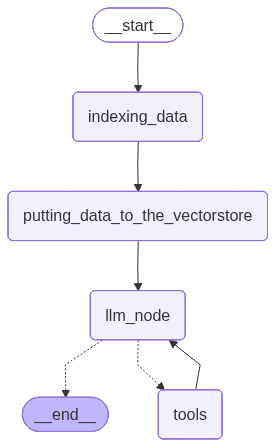

In [16]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [6]:
data_frame = pandas.read_excel("attributes.xlsx")
data_frame

,Attribute,Value
0,Valve type,"Gate valve, wedge"
1,"Nominal diameter, mm",100
2,"Nominal pressure, MPa",1.6
3,Working medium,"Water, steam"
4,"Working medium temperature, C",120
5,Body material,Grey cast iron GG-20
6,Seal material,Stainless steel 12Cr18Ni9Ti
7,Actuator type,Manual handwheel
8,"Face-to-face length, mm",250
9,"Weight, kg",18.5


In [21]:
SYSTEM_PROMPT = """you are helpful assistant for searching information"""

result = graph.invoke({"messages": [{'role': 'system', 'content': SYSTEM_PROMPT}, {'role': 'user', 'content': 'Can you help me find information about pressure'}]})

for f in result["messages"]:
    f.pretty_print()


Retrieved documents: [Document(id='9dd4599b-3d5b-4766-8eff-bec7b0f6257c', metadata={'source': 'rules.txt'}, page_content='PRESSURE\n\nAll pressure values in the system must be expressed exclusively in megapascals (MPa).\nThe use of bar, atm, kgf/cm2, or psi is not permitted. If a source document contains\npressure in bar, convert it before entry: 1 bar equals 0.1 MPa. If the source uses\npsi, apply the factor 1 psi = 0.006895 MPa. Nominal pressure must not exceed the\nallowable rating for the given valve class. The standard nominal pressure series\nincludes PN 1.6, PN 2.5, and PN 4.0 MPa. Any value outside this series requires\nexplicit engineering justification. Reference: GOST 356-80, clause 3.1.'), Document(id='7395bec0-b6d0-417e-b4b1-e073cd2f8943', metadata={'source': 'rules.txt'}, page_content='LEAKAGE AND CONNECTION\n\nThe valve must comply with the leakage class declared in its specification. Class A\ndenotes zero leakage and is required for steam and gas applications. Class B i